In [1]:
import PyDSTool as dst
import numpy as np
import matplotlib.pyplot as plt
from PyDSTool.Toolbox import phaseplane as pp


In [37]:
DSargs = dst.args(name='Lorenz')
pars = {
    "C": 2.0,
    "g_K_bar": 20.0,
    "g_Na_bar" : 20.0,
    "g_NaP_bar" : 0.12,
    "g_shunt" : 2.0,
    "g_adapt_bar" : 1.0,
    "E_K" : -100,
    "E_Na" : 50,
    "E_shunt" : -70,
    "phi_w": 0.25,
    "tau_z": 200,
    "beta_w": -9.0,
    "beta_z": -30,
    "beta_m": -1.2,
    "beta_p": -52.0,
    "gamma_w": 10,
    "gamma_z": 5.0,
    "gamma_m": 18,
    "gamma_p": 12.0,
    "I_stim": 45.0
}

# Define aux functions
fnspecs = {
    "m_inf": (['V'], "0.5*(1+tanh((V-beta_m)/gamma_m))"),
    "w_inf": (['V'], "0.5*(1+tanh((V-beta_w)/gamma_w))"),
    "tau_w": (['V'], "1/(cosh((V-beta_w)/(2*gamma_w)))"),
    "p_inf": (['V'], "0.5*(1+tanh((V-beta_p)/gamma_p))"),
    "I_NaP": (['V'], "g_NaP_bar*p_inf(V)*(V-E_Na)"),
    
}


# Define the ODEs.
varspecs = {
    "V":  "(I_stim  - g_Na_bar*m_inf(V)*(V-E_Na) - I_NaP(V) -  g_K_bar*w*(V-E_K)- g_shunt*(V-E_shunt) - g_adapt_bar*z*(V-E_K))/C",
    "w": "phi_w*(w_inf(V)-w)/tau_w(V)",
    "z": "1/tau_z*(1/(1+exp((beta_z-V)/gamma_z))-z)",

}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "V": -70,
    "w": 0,
    "z": 0
}   

# Define a domain for V. It is needed when finding steady states.
domain = {
    "V": [-100, 100],
    "w": [0, 1],
    "z": [0, 1]
}


DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

Computing trajectory...
Plotting trajectory part A...


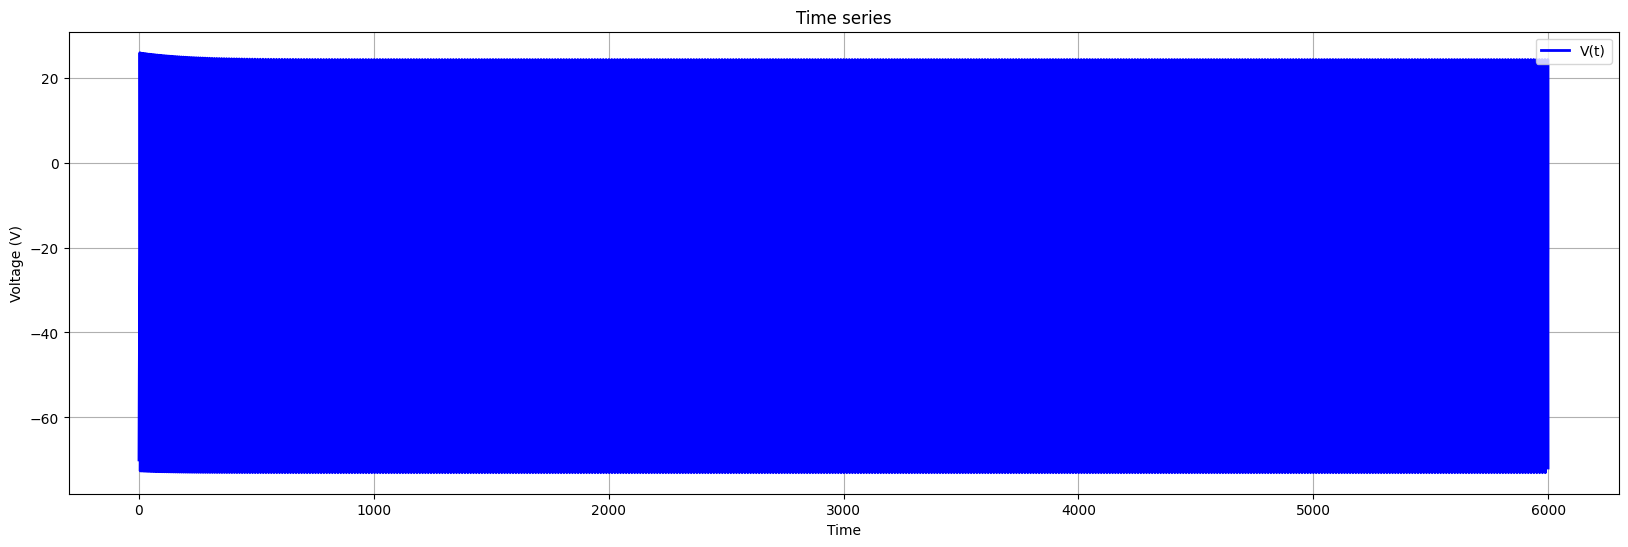

In [38]:

# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define the range of time.
ode_sys.set(tdata=[0, 6000])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

# 3. Plotting Part A: Time Series and Basic Trajectory
print("Plotting trajectory part A...")
plt.figure(figsize=(20, 6))
plt.plot(points['t'], points['V'], 'b', lw =2, label = 'V(t)')
plt.xlabel('Time')
plt.ylabel("Voltage (V)")
plt.title('Time series')
plt.grid(True)
plt.legend()
plt.show()


Plotting trajectory part A...


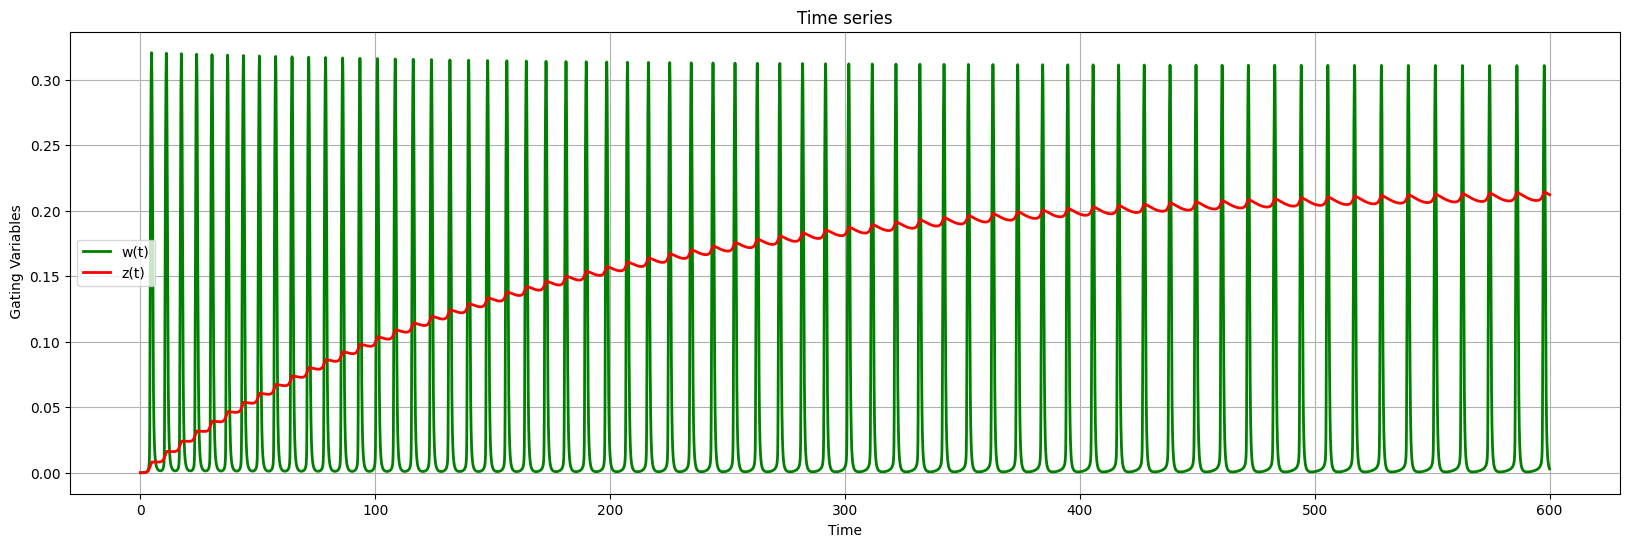

In [4]:


# 3. Plotting Part A: Time Series and Basic Trajectory
print("Plotting trajectory part A...")
plt.figure(figsize=(20, 6))
plt.plot(points['t'], points['w'], 'g', lw = 2, label = "w(t)")
plt.plot(points['t'], points['z'], 'r', lw = 2, label = "z(t)")
plt.xlabel('Time')
plt.ylabel(" Gating Variables")
plt.title('Time series')
plt.grid(True)
plt.legend()
plt.show()


In [46]:
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define the range of time.
ode_sys.set(tdata=[0, 30])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

fp_coord = pp.find_fixedpoints(ode_sys, n = 4, eps = 1e-8)[0]
print(fp_coord)
pycont = dst.ContClass(ode_sys)
pcargs = dst.args(name='EQ1', type='EP-C')
pcargs.freepars = ['I_stim']
pcargs.MaxNumPoints = 200
pcargs.MaxStepSize = 1
pcargs.MinStepSize = 1e-3
pcargs.LocBifPoints = 'all'
pcargs.SaveEigen = True
pcargs.SaveJacobian = True

pcargs.initpoint = fp_coord
pcargs.verbosity = 2
pycont.newCurve(pcargs)
pycont["EQ1"].forward()
pycont["EQ1"].backward()

Computing trajectory...
{'V': -35.44319816464566, 'w': 0.005023263007554301, 'z': 0.25187453092820966}
Maximum test function iterations reached.

Checking...
  |q| = 1.000000
  |<p,q> - 1| =  2.3714374201337736e-16
  |Aq - iwq| = 0.000000
  |A*p + iwp| = 0.000008

H Point found 
0 : 
V  =  -37.04741939847074
w  =  0.00364959109367545
z  =  0.1963154748499022
I_stim  =  41.37259767293073

Eigenvalues = 

     (0.000000,0.152482)
     (0.000000,-0.152482)
     (-0.118905,0.000000)


w = 0.15248208536232463
l1 = -0.005339402423763313

Maximum test function iterations reached.

B Point found 
0 : 
V  =  -99.99999999923693
w  =  1.2469252630431533e-08
z  =  8.315280277910352e-07
I_stim  =  -60.05726643884317



Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (I_stim, V) space')

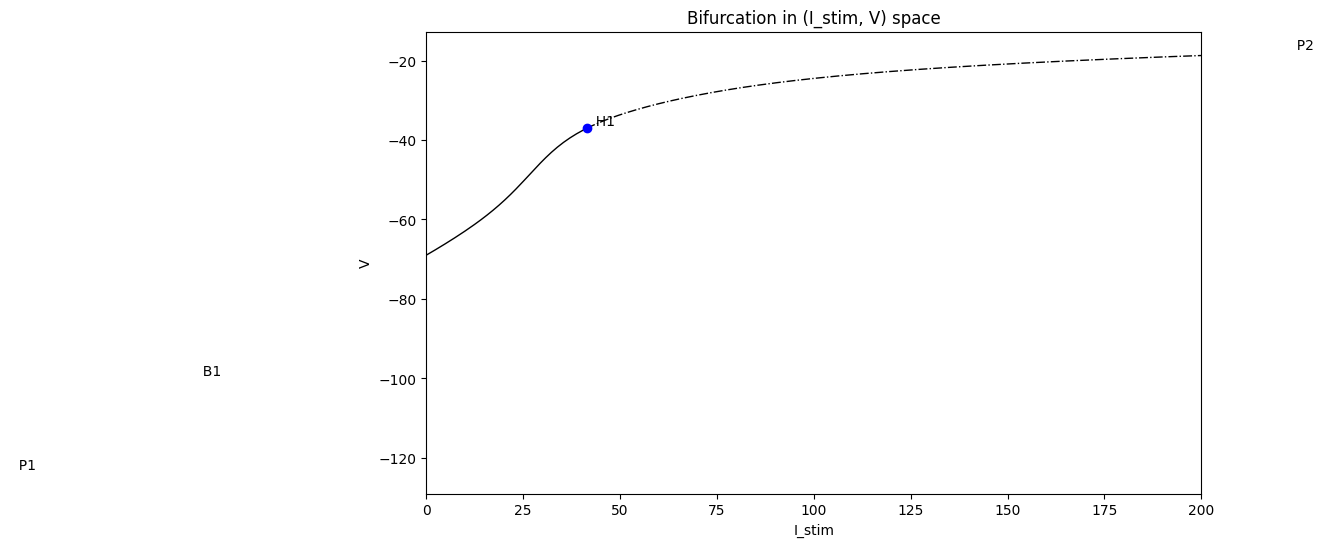

In [47]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
plt.xlim(0, 200)
pycont.display(('I_stim', 'V'), stability=True)
plt.title("Bifurcation in (I_stim, V) space")

In [19]:
DSargs = dst.args(name='Lorenz')
pars = {
    "C": 2.0,
    "g_K_bar": 20.0,
    "g_Na_bar" : 20.0,
    "g_NaP_bar" : 0.012,
    "g_shunt" : 2.0,
    "g_adapt_bar" : 1.0,
    "E_K" : -100,
    "E_Na" : 50,
    "E_shunt" : -70,
    "phi_w": 0.25,
    "tau_z": 200,
    "beta_w": -9.0,
    "beta_z": -30,
    "beta_m": -1.2,
    "beta_p": -52.0,
    "gamma_w": 10,
    "gamma_z": 5.0,
    "gamma_m": 18,
    "gamma_p": 12.0,
    "I_stim": 45.0
}

# Define aux functions
fnspecs = {
    "m_inf": (['V'], "0.5*(1+tanh((V-beta_m)/gamma_m))"),
    "w_inf": (['V'], "0.5*(1+tanh((V-beta_w)/gamma_w))"),
    "tau_w": (['V'], "1/(cosh((V-beta_w)/(2*gamma_w)))"),
    "p_inf": (['V'], "0.5*(1+tanh((V-beta_p)/gamma_p))"),
    "I_NaP": (['V'], "g_NaP_bar*p_inf(V)*(V-E_Na)"),
    
}


# Define the ODEs.
varspecs = {
    "V":  "(I_stim  - g_Na_bar*m_inf(V)*(V-E_Na) - I_NaP(V) -  g_K_bar*w*(V-E_K)- g_shunt*(V-E_shunt) - g_adapt_bar*z*(V-E_K))/C",
    "w": "phi_w*(w_inf(V)-w)/tau_w(V)",
    "z": "1/tau_z*(1/(1+exp((beta_z-V)/gamma_z))-z)",

}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "V": -70,
    "w": 0,
    "z": 0
}   

# Define a domain for V. It is needed when finding steady states.
domain = {
    "V": [-100, 100],
    "w": [0, 1],
    "z": [0, 1]
}


DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

Computing trajectory...
Plotting trajectory part A...


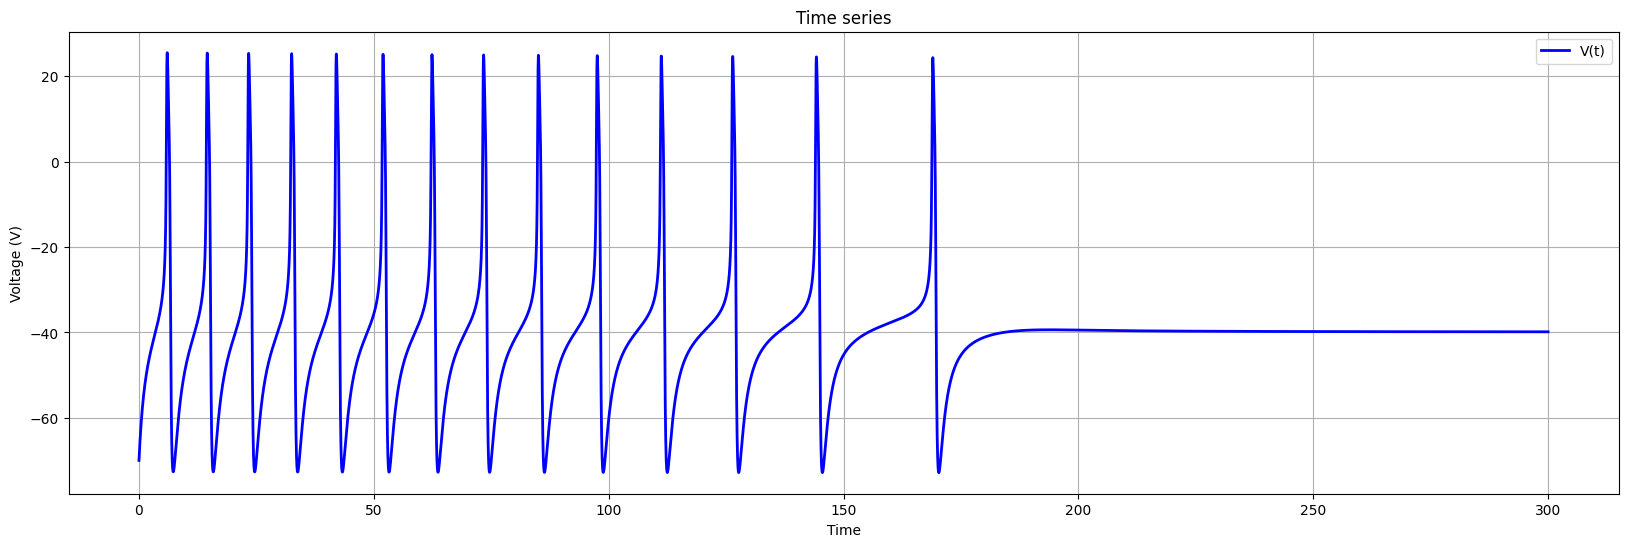

In [8]:

# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define the range of time.
ode_sys.set(tdata=[0, 300])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

# 3. Plotting Part A: Time Series and Basic Trajectory
print("Plotting trajectory part A...")
plt.figure(figsize=(20, 6))
plt.plot(points['t'], points['V'], 'b', lw =2, label = 'V(t)')
plt.xlabel('Time')
plt.ylabel("Voltage (V)")
plt.title('Time series')
plt.grid(True)
plt.legend()
plt.show()


Plotting trajectory part A...


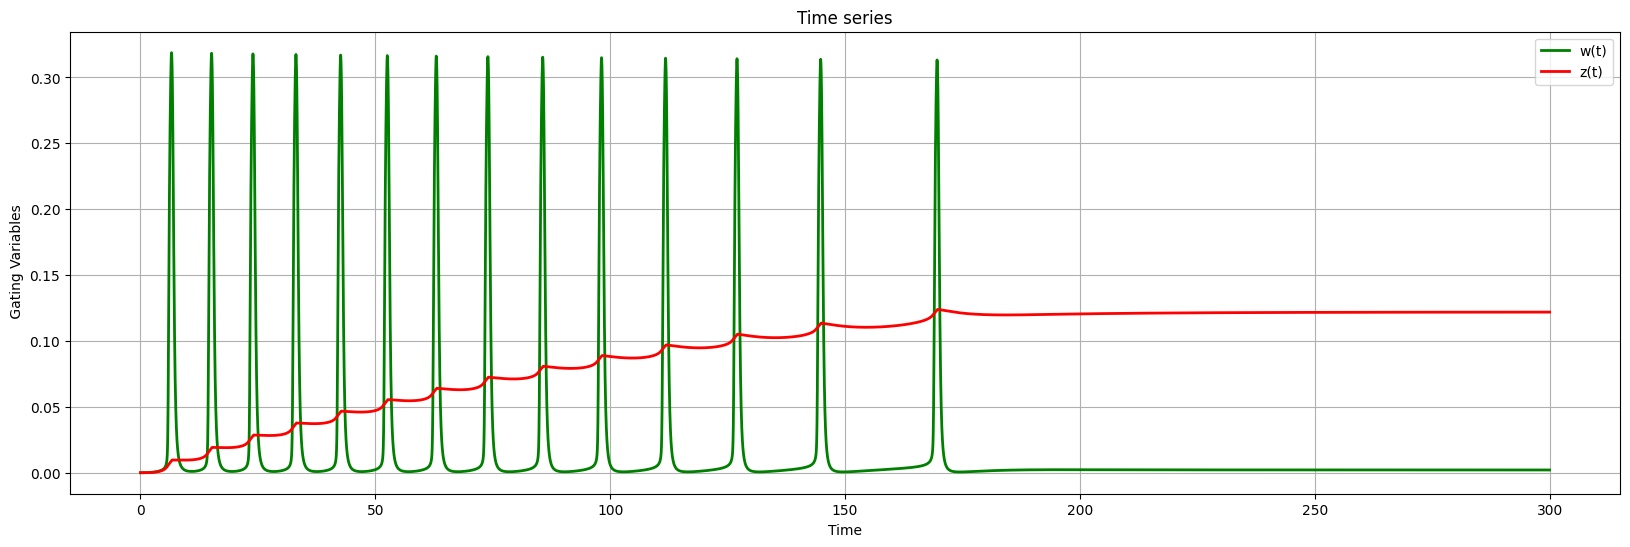

In [9]:


# 3. Plotting Part A: Time Series and Basic Trajectory
print("Plotting trajectory part A...")
plt.figure(figsize=(20, 6))
plt.plot(points['t'], points['w'], 'g', lw = 2, label = "w(t)")
plt.plot(points['t'], points['z'], 'r', lw = 2, label = "z(t)")
plt.xlabel('Time')
plt.ylabel(" Gating Variables")
plt.title('Time series')
plt.grid(True)
plt.legend()
plt.show()


In [20]:
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define the range of time.
ode_sys.set(tdata=[0, 30])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

fp_coord = pp.find_fixedpoints(ode_sys, n = 4, eps = 1e-8)[0]
print(fp_coord)
pycont = dst.ContClass(ode_sys)
pcargs = dst.args(name='EQ1', type='EP-C')
pcargs.freepars = ['I_stim']
pcargs.MaxNumPoints = 100
pcargs.MaxStepSize = 1
pcargs.MinStepSize = 1e-3
pcargs.LocBifPoints = 'all'
pcargs.SaveEigen = True
pcargs.SaveJacobian = True

pcargs.initpoint = fp_coord
pcargs.verbosity = 2
pycont.newCurve(pcargs)
pycont["EQ1"].forward()
pycont["EQ1"].backward()

Computing trajectory...
{'V': -39.86993386220073, 'w': 0.0020785857976230557, 'z': 0.12196131246230468}
Maximum test function iterations reached.

Checking...
  |q| = 1.000000
  |<p,q> - 1| =  4.518280359883027e-16
  |Aq - iwq| = 0.000000
  |A*p + iwp| = 0.000010

H Point found 
0 : 
V  =  -36.960769529651955
w  =  0.0037131527346406785
z  =  0.19906412065613166
I_stim  =  50.234954606176785

Eigenvalues = 

     (-0.000000,0.158214)
     (-0.000000,-0.158214)
     (-0.111658,0.000000)


w = 0.15821350325605626
l1 = -0.012273808656988346

Test function going crazy:  class Hopf_Bor(BorderMethod, BiAltMethod) 



Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (I_stim, V) space')

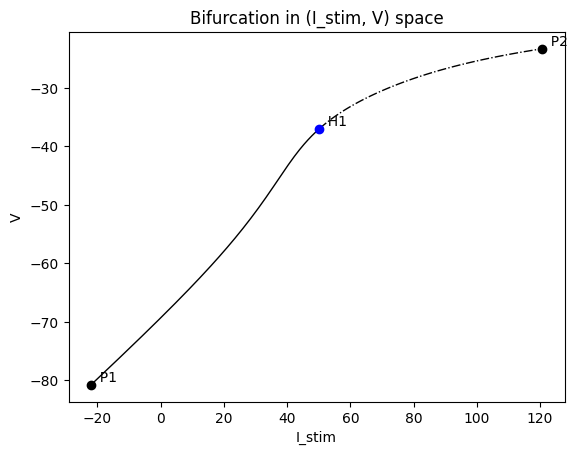

In [22]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
pycont.display(('I_stim', 'V'), stability=True)
plt.title("Bifurcation in (I_stim, V) space")

In [33]:
DSargs = dst.args(name='Lorenz')
pars = {
    "C": 2.0,
    "g_K_bar": 20.0,
    "g_Na_bar" : 20.0,
    "g_NaP_bar" : 0.012,
    "g_shunt" : 2.0,
    "g_adapt_bar" : 1.0,
    "E_K" : -100,
    "E_Na" : 50,
    "E_shunt" : -70,
    "phi_w": 0.25,
    "tau_z": 200,
    "beta_w": -9.0,
    "beta_z": -30,
    "beta_m": -1.2,
    "beta_p": -52.0,
    "gamma_w": 10,
    "gamma_z": 5.0,
    "gamma_m": 18,
    "gamma_p": 12.0,
    "I_stim": 45.0
}

# Define aux functions
fnspecs = {
    "m_inf": (['V'], "0.5*(1+tanh((V-beta_m)/gamma_m))"),
    "w_inf": (['V'], "0.5*(1+tanh((V-beta_w)/gamma_w))"),
    "tau_w": (['V'], "1/(cosh((V-beta_w)/(2*gamma_w)))"),
    "p_inf": (['V'], "0.5*(1+tanh((V-beta_p)/gamma_p))"),
    "I_NaP": (['V'], "g_NaP_bar*p_inf(V)*(V-E_Na)"),
    
}


# Define the ODEs.
varspecs = {
    "V":  "(I_stim  - g_Na_bar*m_inf(V)*(V-E_Na) - I_NaP(V) -  g_K_bar*w*(V-E_K))",
    "w": "phi_w*(w_inf(V)-w)/tau_w(V)",
    "z": "1/tau_z*(1/(1+exp((beta_z-V)/gamma_z))-z)",

}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "V": -70,
    "w": 0,
    "z": 0
}   

# Define a domain for V. It is needed when finding steady states.
domain = {
    "V": [-100, 100],
    "w": [0, 1],
    "z": [0, 1]
}


DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

In [34]:
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

# Define the range of time.
ode_sys.set(tdata=[0, 30])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

fp_coord = pp.find_fixedpoints(ode_sys, n = 4, eps = 1e-8)[0]
print(fp_coord)
pycont = dst.ContClass(ode_sys)
pcargs = dst.args(name='EQ1', type='EP-C')
pcargs.freepars = ['I_stim']
pcargs.MaxNumPoints = 200
pcargs.MaxStepSize = 1
pcargs.MinStepSize = 1e-3
pcargs.LocBifPoints = 'all'
pcargs.SaveEigen = True
pcargs.SaveJacobian = True

pcargs.initpoint = fp_coord
pcargs.verbosity = 2
pycont.newCurve(pcargs)
pycont["EQ1"].forward()

Computing trajectory...
{'V': -18.17059867181436, 'w': 0.1377482266310102, 'z': 0.9141882261591581}


Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (I_stim, V) space')

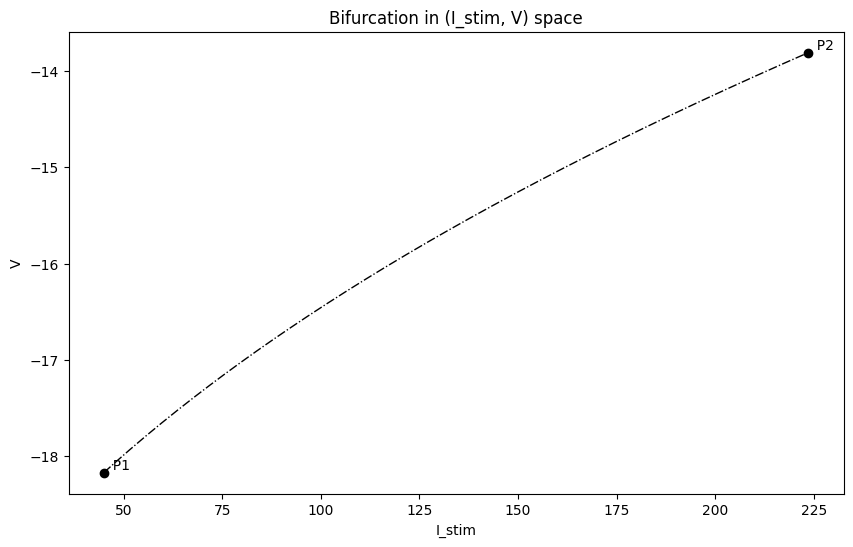

In [35]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
pycont.display(('I_stim', 'V'), stability=True)
plt.title("Bifurcation in (I_stim, V) space")